# HMT-Agrivoltaics: demonstration

This notebook walks through the heat and mass transfer model for semi-transparent PV modules installed above an
orchard (Amorós-Trepat et al., under review). For every hour, the model solves the energy balance of each module in a
row together with the air flowing underneath, which picks up heat and moisture from the soil and the trees. The result
is the temperature of each module and the temperature and humidity of the air below it.

To keep the example short, we run a single summer day (`example_input_1day.csv`, hourly values). The system
properties are fixed values from the Bierbeek case study. Where a property can also be calculated from measured or
spectral data, the comment next to it points to the function that does so.

The notebook is organised as follows:

1. System properties: geometry, optics and layer stack of the module, and crop and soil parameters (`thermal_mass_PV`, `absorption_avg`)
2. Input time series, read from the example file
3. Air properties (`calc_air_properties`)
4. Soil and crop: evapotranspiration (`ET_func.ET0_calc`, `ET_func.Kcb_calc`, `ET_func.Ke_ET_calc`), ground temperature and Bowen ratio (`Tground_Gn_calc`)
5. Module temperature (`Tm_model`)
6. Results


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import functions_module as func
import ET_func

## 1. System properties

Geometry of the row, optical properties of the module and its layer stack. The optical constants are the values
calculated for the case study of the manuscript (Bierbeek, Belgium).


In [2]:
# GEOMETRY OF THE SYSTEM
num_modules = 12  # number of modules in the row (in the direction of the air flow)
module_width = 0.991  # m
module_length = 1.649  # m
module_height = 4.2  # m, height of the modules above the ground
tilt_angle = 12  # deg, module tilt
crop_height = 2.4  # m, height of the crop (orchard trees)

# OPTICAL PROPERTIES OF THE MODULE [-]
absorption_cell = 0.727  # alternatively, use func.alpha_cell_calc(wavelength_nm, irradiance_spectrum, E_g=1.12, spectral_response=<file>, cell_reflectance=<file>)
emissivity_cell = 0.854  # alternatively, use func.emissivity_T_calc(wl_um, absorption_cell_spectral, T_module) with the spectral cell absorptance
absorption_glass = 0.046  # alternatively, use func.alpha_glass_spectral_calc_dynamic(n, k, total_glass_thickness, wl_um, AOI) with glass n, k files
emissivity_glass = 0.149  # alternatively, use func.emissivity_T_calc(wl_um, alpha_glass_spectral, T_module) with the spectral glass absorptance
packing_factor = 0.6  # cell area / module area [-]

# MODULE LAYER STACK: (specific heat [J/kg K], density [kg/m3], thickness [m], thermal conductivity [W/m K])
# Keep the front glass as the first layer and the solar cells as the fourth layer: their properties are averaged
# with the packing factor.
glass_thickness = 0.0032  # m
layers_data = [
    (500, 3000, glass_thickness, 1.8),  # Front glass
    (2090, 950, 500e-6, 0.35),  # Front encapsulant (EVA)
    (691, 2400, 100e-9, 32),  # Anti-reflection coating
    (677, 2330, 225e-6, 148),  # Monocrystalline silicon cells
    (691, 2400, 100e-9, 32),  # Anti-reflection coating
    (2090, 950, 500e-6, 0.35),  # Back encapsulant (EVA)
    (500, 3000, glass_thickness, 1.8),  # Rear transparent layer
]

# CROP (FAO-56 dual crop coefficient): growth stages [days] and basal crop coefficients [-] of the orchard
Start_growth = 90  # day of the year when growth starts
Lini, Ldev, Lmid, Llate = 20, 70, 90, 30  # length of the initial, development, mid-season and late-season stages
Kcb_nul, Kcb_ini, Kcb_mid, Kcb_end = 0.45, 0.50, 0.90, 0.70  # dormancy, initial, mid-season and end values
Kc_min = 0.15  # minimum crop coefficient of the bare soil [-]
fw = 1  # fraction of the soil surface wetted by irrigation or rain [-]

# SOIL (sandy loam)
theta = 0.18  # volumetric water content [m3/m3]
soil_type = "Sandy loam"  # "Sandy loam", "Clay" or "Silt"
TEW = 1000 * (0.27 - 0.07) * 0.1  # total evaporable water [mm]: 1000 (field capacity - 0.5 wilting point) depth of the evaporation layer
REW = 6  # readily evaporable water [mm]

# MODULE PROPERTIES
mc = func.thermal_mass_PV(layers_data, packing_factor)  # thermal mass [J/m2 K]
absorption = func.absorption_avg(absorption_glass, absorption_cell, packing_factor)  # module absorptance [-]
emissivity = packing_factor * emissivity_cell + (1 - packing_factor) * emissivity_glass  # module emissivity [-]
print(f"Thermal mass {mc:.0f} J/m2K, absorptance {absorption:.3f}, emissivity {emissivity:.3f}")

Thermal mass 11940 J/m2K, absorptance 0.455, emissivity 0.572


## 2. Time series inputs

`example_input_1day.csv` contains one artificial clear summer day at hourly resolution: weather, irradiance on the
module, on a reference grass surface and on the ground below the modules, precipitation and irrigation.


In [3]:
data = pd.read_csv("example_input_1day.csv", parse_dates=["time"])
times = pd.DatetimeIndex(data["time"])

# Weather (measured at a weather station)
Tair_C = data["Tair_C"].to_numpy()  # ambient air temperature [degC]
Tair_K = Tair_C + 273.15  # [K]
RH = data["RH"].to_numpy()  # relative humidity [-]
pressure = data["pressure_Pa"].to_numpy()  # atmospheric pressure [Pa]
wind_speed_2m = data["wind_speed_2m_ms"].to_numpy()  # wind at 2 m height [m/s], for the reference evapotranspiration
wind_speed = data["wind_speed_ms"].to_numpy()  # wind along the rows at module height [m/s]; alternatively, scale a measured wind with func.wind_speed_calc

# Irradiance [W/m2]; alternatively, use func.radiation (transposition model) or a ray-tracing model
G_module = data["G_module_Wm2"].to_numpy()  # incident on the module, front and rear
G_grass = data["G_grass_Wm2"]  # on a reference grass surface in the open
G_ground = data["G_ground_Wm2"]  # on the ground below the modules and trees
poa_global_absorbed = G_module * absorption  # heat absorbed by the module [W/m2]

# Water inputs, daily totals [mm/day]
precipitation_day = data["precipitation_mm"].to_numpy().reshape(-1, 24).sum(axis=1)
net_irr = data["irrigation_mm"].to_numpy().reshape(-1, 24).sum(axis=1)  # net irrigation; alternatively, from CROPWAT with ET_files.create_irrigation_file

data.head()

,time,Tair_C,RH,pressure_Pa,wind_speed_2m_ms,wind_speed_ms,G_module_Wm2,G_grass_Wm2,G_ground_Wm2,precipitation_mm,irrigation_mm
0,2024-07-24 00:00:00,15.8180,0.8897,101000.0,1.0,0.8,0.0,0.0,0.0,0.0,0.0
1,2024-07-24 01:00:00,15.1029,0.9278,101000.0,1.0,0.8,0.0,0.0,0.0,0.0,0.0
2,2024-07-24 02:00:00,14.6533,0.9518,101000.0,1.0,0.8,0.0,0.0,0.0,0.0,0.0
3,2024-07-24 03:00:00,14.5000,0.9600,101000.0,1.0,0.8,0.0,0.0,0.0,0.0,0.0
4,2024-07-24 04:00:00,14.6533,0.9518,101000.0,1.0,0.8,0.0,0.0,0.0,0.0,0.0


## 3. Ambient air properties

Density, kinematic viscosity, thermal conductivity, thermal diffusivity and dew point of the ambient air at each hour.


In [8]:
air = np.array([func.calc_air_properties(float(T), float(rh), float(p)) for T, rh, p in zip(Tair_K, RH, pressure)])
dynamic_viscosity, density, kinematic_viscosity, Cp, thermal_conductivity, diffusivity, dew_point = air.T

## 4. Soil-crop system

Evapotranspiration of the orchard with the FAO-56 dual crop coefficient method, and ground surface temperature and
Bowen ratio from the 1D soil heat diffusion model with an energy balance at the ground surface. Together they give the
latent and sensible heat released by the soil-crop system into the air below the modules.

Note: the soil model starts from the air temperature, so one day is a short spin-up; in practice, run a full year.


thermal_diffusivity = 4.40e-07, Cv_s = 3540400.00, lambda_soil = 1.56
Day: Kcb = 0.868, Ke = 0.301, ET0 = 5.74 mm/day, ETc = 6.71 mm/day
Latent heat flux: mean 190 W/m2, ground surface temperature: 15.8-16.3 degC


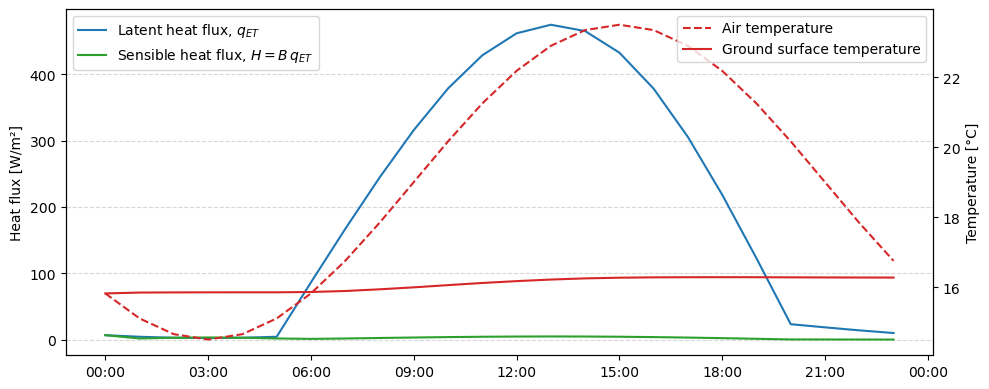

In [9]:
# Daily values of the example day
wind_speed_2m_day = wind_speed_2m.reshape(-1, 24).mean(axis=1)  # [m/s]
RHmin_day = RH.reshape(-1, 24).min(axis=1)  # [-]

# Reference evapotranspiration of a grass surface (FAO-56 Penman-Monteith), hourly [mm/day] and latent heat flux [W/m2]
ET0, ET0_day, ET0_FAO_day, ET0_FAO_h, q_ET0_Wm2 = ET_func.ET0_calc(
    wind_speed_2m, wind_speed_2m_day, Tair_C, dew_point, RH, pressure, G_grass, density, Cp
)

# Basal crop coefficient of the orchard: Kcb_calc builds the crop calendar over a full year (365 days), here with the
# daily wind and minimum humidity of the example day, and the value of its day of the year is taken
doy = times[0].dayofyear
Kcb_table, Kcb_fluct, Kcb_year = ET_func.Kcb_calc(
    np.full(365, wind_speed_2m_day[0]), np.full(365, RHmin_day[0] * 100), crop_height,
    Lini, Ldev, Lmid, Llate, Start_growth, Kcb_nul, Kcb_ini, Kcb_mid, Kcb_end,
)
Kcb_day = Kcb_year[doy - 1 : doy]

# Soil evaporation coefficient and crop evapotranspiration (dual crop coefficient)
Ke_day, Ke, Kcb, ET, ETc_day, Kr, fc, De_day, q_ETc_day, q_ET = ET_func.Ke_ET_calc(
    ET0, ET0_day, Kcb_day, wind_speed_2m_day, RHmin_day * 100, net_irr, precipitation_day,
    Kc_min, fw, TEW, REW, crop_height,
)  # ET: crop evapotranspiration [mm/day], q_ET: latent heat flux [W/m2], hourly

# Ground surface temperature and Bowen ratio (1D soil heat diffusion and ground surface energy balance)
L_ET = pd.Series(np.asarray(q_ET0_Wm2) * Kcb)  # latent heat flux at the ground surface (basal component) [W/m2]
soil = func.Tground_Gn_calc(pd.Series(G_ground.to_numpy()), L_ET, pressure, Cp, Tair_C, RH, theta, soil_type)
Tground_C = soil["T_surface"]  # ground surface temperature [degC]
B = np.asarray(soil["B"])  # Bowen ratio [-], limited to 0.01-5
H = B * np.asarray(q_ET)  # sensible heat flux released by the soil-crop system [W/m2]

print(f"Day: Kcb = {Kcb_day[0]:.3f}, Ke = {Ke_day[0]:.3f}, ET0 = {ET0_day.iloc[0]:.2f} mm/day, ETc = {ETc_day[0]:.2f} mm/day")
print(f"Latent heat flux: mean {np.mean(q_ET):.0f} W/m2, ground surface temperature: {Tground_C.min():.1f}-{Tground_C.max():.1f} degC")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(times, np.asarray(q_ET), color="tab:blue", label="Latent heat flux, $q_{ET}$")
ax.plot(times, H, color="tab:green", label="Sensible heat flux, $H = B\\,q_{ET}$")
ax.set_ylabel("Heat flux [W/m²]")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.grid(True, axis="y", linestyle="--", alpha=0.5)
ax.legend(loc="upper left")
ax2 = ax.twinx()
ax2.plot(times, Tair_C, color="tab:red", linestyle="--", label="Air temperature")
ax2.plot(times, np.asarray(Tground_C), color="tab:red", label="Ground surface temperature")
ax2.set_ylabel("Temperature [°C]")
ax2.legend(loc="upper right")
fig.tight_layout()
plt.show()

## 5. Module temperature solver

`func.Tm_model` solves, for each hour and each module along the row, the energy balance of the module (absorbed
irradiance, convection on the top and bottom surfaces, long-wave radiation to the sky and to the ground, thermal mass)
together with the energy and water balance of the air below the module. The air leaving one module enters the next one.


In [10]:
(
    Tm,
    Gr,
    hconv_top,
    tground,
    h_forced_top,
    h_free_top,
    h_ground,
    tsky,
    hsky,
    hconv_bot,
    Tair_bot,
    Tout_bot,
    mair_bot,
    q_vent,
    RH_out,
) = func.Tm_model(
    emissivity,
    tilt_angle,
    module_width,
    module_length,
    dew_point,
    num_modules,
    mc,
    poa_global=poa_global_absorbed,
    Tair_K=Tair_K,
    wind_speed=wind_speed,
    Tground_C=Tground_C,
    RH=RH,
    pressure=pressure,
    times=times,
    ET=ET,
    H=H,
    Kcb=Kcb,
    Ke=Ke,
    density=density,
    kinematic_viscosity=kinematic_viscosity,
    thermal_conductivity=thermal_conductivity,
    diffusivity=diffusivity,
    module_height=module_height,
    crop_height=crop_height,
)
Tair_bot_C = np.array(Tair_bot) - 273.15  # air below each module [degC], shape (module, hour)
RH_out = np.array(RH_out)  # relative humidity of the air leaving each module [-], shape (module, hour)
q_vent = np.array(q_vent)  # heat removed by the air flow below each module [W], shape (module, hour)
print(f"Mean module temperature: first module {Tm.iloc[:, 0].mean():.2f} degC, last module {Tm.iloc[:, -1].mean():.2f} degC")

Hour 0
Hour 0, Module 0, wind:0.800 ,Tair: 288.968, Tin: 288.968, Tbot = 288.968, Tout: 288.968, q_vent: -0.748, H_ET: 10.658, q_conv,bot: -9.910
Hour 0, Module 1, wind:0.800 ,Tair: 288.968, Tin: 288.968, Tbot = 288.968, Tout: 288.968, q_vent: -0.747, H_ET: 10.658, q_conv,bot: -9.911
Hour 0, Module 2, wind:0.800 ,Tair: 288.968, Tin: 288.968, Tbot = 288.968, Tout: 288.969, q_vent: -0.746, H_ET: 10.658, q_conv,bot: -9.912
Hour 0, Module 3, wind:0.800 ,Tair: 288.968, Tin: 288.969, Tbot = 288.969, Tout: 288.969, q_vent: -0.745, H_ET: 10.658, q_conv,bot: -9.913
Hour 0, Module 4, wind:0.800 ,Tair: 288.968, Tin: 288.969, Tbot = 288.969, Tout: 288.969, q_vent: -0.744, H_ET: 10.658, q_conv,bot: -9.914
Hour 0, Module 5, wind:0.800 ,Tair: 288.968, Tin: 288.969, Tbot = 288.969, Tout: 288.969, q_vent: -0.744, H_ET: 10.658, q_conv,bot: -9.914
Hour 0, Module 6, wind:0.800 ,Tair: 288.968, Tin: 288.969, Tbot = 288.969, Tout: 288.969, q_vent: -0.743, H_ET: 10.658, q_conv,bot: -9.915
Hour 0, Module 7, wi

## 6. Results


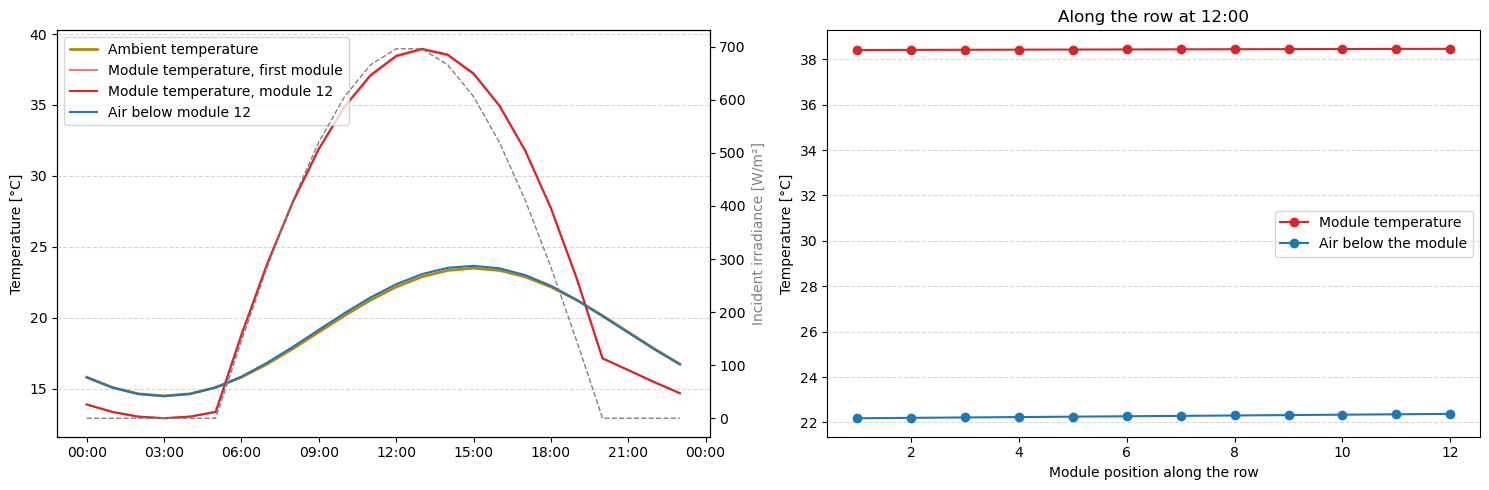

,Tm_Module_1,Tm_Module_12,Tair_bot_Module_12
count,24.00,24.00,24.00
mean,24.50,24.52,19.07
std,10.11,10.14,3.32
min,12.93,12.93,14.49
25%,14.50,14.49,15.85
50%,23.29,23.30,19.06
75%,34.87,34.92,22.29
max,38.91,38.96,23.67


In [7]:
modules = np.arange(1, num_modules + 1)
noon = int(np.argmax(G_module))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(times, Tair_K - 273.15, color="#B8860B", linewidth=2, label="Ambient temperature")
ax[0].plot(times, Tm.iloc[:, 0], color="#D62728", alpha=0.6, label="Module temperature, first module")
ax[0].plot(times, Tm.iloc[:, -1], color="#D62728", label=f"Module temperature, module {num_modules}")
ax[0].plot(times, Tair_bot_C[-1], color="#1f77b4", label=f"Air below module {num_modules}")
ax[0].set_ylabel("Temperature [°C]")
ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax[0].legend(loc="upper left")
ax2 = ax[0].twinx()
ax2.plot(times, G_module, color="gray", linestyle="--", linewidth=1)
ax2.set_ylabel("Incident irradiance [W/m²]", color="gray")

ax[1].plot(modules, Tm.iloc[noon, :], marker="o", color="#D62728", label="Module temperature")
ax[1].plot(modules, Tair_bot_C[:, noon], marker="o", color="#1f77b4", label="Air below the module")
ax[1].set_xlabel("Module position along the row")
ax[1].set_ylabel("Temperature [°C]")
ax[1].set_title(f"Along the row at {times[noon]:%H:%M}")
ax[1].legend()
for a in ax:
    a.grid(True, axis="y", linestyle="--", alpha=0.5)
fig.tight_layout()
plt.show()

# Save the results
results = pd.DataFrame(index=times)
for m in modules:
    results[f"Tm_Module_{m}"] = Tm.iloc[:, m - 1].to_numpy()  # degC
    results[f"Tair_bot_Module_{m}"] = Tair_bot_C[m - 1]  # degC
    results[f"RH_out_Module_{m}"] = RH_out[m - 1]  # [-]
    results[f"q_vent_Module_{m}"] = q_vent[m - 1]  # W
os.makedirs("Results", exist_ok=True)
results.to_csv("Results/Results_demonstration_1day.csv", index_label="time")
results[[f"Tm_Module_1", f"Tm_Module_{num_modules}", f"Tair_bot_Module_{num_modules}"]].describe().round(2)